### **Project Overview**
This project aims to build an end-to-end **recommendation system** using **K-Means clustering** (unsupervised learning) on the **cleaned_titles.csv** dataset. Here I will be using **Multi-Hot Encoding** for genres and production_countries columns, **TF-IDF** for plot descriptions, and **Log + Min-Max Scaling** for numerical scores before training **K-Means**.

In [ ]:
# Importing Required Libraries
import os
import pandas as pd
import numpy as np
import joblib
import streamlit as st
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
# Loading the clean dataset
df = pd.read_pickle('../data/processed/cleaned_titles.pkl')

In [16]:
# Checking shape, missing values, and sample rows
print("Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
df.head(10)

Shape: (1904, 16)

Missing Values:
 id                      0
title                   0
type                    0
description             0
release_year            0
age_certification       0
runtime                 0
genres                  0
production_countries    0
seasons                 0
imdb_id                 0
imdb_score              0
imdb_votes              0
tmdb_popularity         0
tmdb_score              0
decade                  0
dtype: int64


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,decade
0,ts299859,Serendipity,SHOW,,1973,Not rated,39,[],[XX],1.0,tt8912714,7.086058,188.5,4.6165,7.330764,1970
1,ts43055,Entertainment Weekly,SHOW,This program -- one of our viewers’ favorites ...,1984,Not rated,60,[reality],[KR],1.0,tt7782444,7.086058,188.5,4.7290,8.500000,1980
2,tm21196,Il Mare,MOVIE,"In the year 1999, a young woman leaves her qua...",2000,Not rated,105,"[fantasy, scifi, romance, drama, documentation]",[KR],0.0,tt0282599,7.500000,8777.0,10.4130,7.500000,2000
3,tm8809,Fight Back to School,MOVIE,Star Chow is about to be kicked out of the Roy...,1991,Not rated,100,"[comedy, action, romance]",[HK],0.0,tt0103045,7.000000,4021.0,5.6160,6.600000,1990
4,ts39072,Inkigayo,SHOW,The program is a weekly music show that featur...,1998,Not rated,69,"[reality, music]",[KR],2.0,tt6050846,5.700000,9.0,2.1540,9.000000,1990
5,tm54496,The Storm Riders,MOVIE,Based on a comic book called Fung Wan (or Tin ...,1998,PG-13,128,"[action, fantasy]",[HK],0.0,tt0165499,6.300000,3910.0,6.9050,6.100000,1990
6,tm118132,The Maidens of Heavenly Mountains,MOVIE,Legend has it that in a faraway place beyond t...,1994,Not rated,96,"[action, fantasy]",[HK],0.0,tt0111776,5.800000,539.0,2.9860,4.700000,1990
7,tm19949,Summer Holiday,MOVIE,Summer Holiday is about a Hong Kong (Sammi Che...,2000,Not rated,98,"[comedy, romance]",[MY],0.0,tt0259741,5.700000,477.0,1.4250,6.300000,2000
8,tm185672,Flirting Scholar,MOVIE,A scholar in search of true love. Disguising h...,1993,Not rated,102,"[romance, comedy]",[HK],0.0,tt0108289,7.500000,5198.0,6.3660,7.100000,1990
9,tm127140,Fight Back to School 2,MOVIE,Star Chow is an officer in the Royal Hong Kong...,1992,Not rated,98,"[comedy, action, crime]",[HK],0.0,tt0105534,6.600000,2594.0,8.0170,6.500000,1990


In [4]:
print(df['genres'].iloc[1])
print(df['production_countries'].iloc[0])

['reality']
['XX']


In [5]:
print(type(df['genres'].iloc[1]))
print(type(df['production_countries'].iloc[0]))

<class 'list'>
<class 'list'>


In [6]:
print(type(df['genres'].iloc[1][0]))
print(type(df['production_countries'].iloc[0][0]))

<class 'str'>
<class 'str'>


In [7]:
feature_cols = ['type', 'description', 'release_year', 'runtime', 'genres', 'production_countries', 
                'seasons', 'imdb_score', 'imdb_votes', 'tmdb_score', 'tmdb_popularity']

X = df[feature_cols].copy()

df_display = df.copy()

In [8]:
print("Feature Table (X) Shape:", X.shape)
print("Display Table shape:",df_display.shape )

Feature Table (X) Shape: (1904, 11)
Display Table shape: (1904, 16)


In [9]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  1904 non-null   object 
 1   description           1904 non-null   object 
 2   release_year          1904 non-null   int64  
 3   runtime               1904 non-null   int64  
 4   genres                1904 non-null   object 
 5   production_countries  1904 non-null   object 
 6   seasons               1904 non-null   float64
 7   imdb_score            1904 non-null   float64
 8   imdb_votes            1904 non-null   float64
 9   tmdb_score            1904 non-null   float64
 10  tmdb_popularity       1904 non-null   float64
dtypes: float64(5), int64(2), object(4)
memory usage: 163.8+ KB


#### **Preprocessing:**
- **One-Hot Encoding:** type
- **Multi-Hot Encoding:**  genres, production_countries
- **TF-IDF:** description
- **MinMax Scaler:** release_year, runtime, seasons, imdb_score, tmdb_score
- **log1p + MinMax Scaler:** imdb_votes, tmdb_popularity

In [10]:
# 1. Applying log1p transform to the two skewed popularity/votes columns
X['imdb_votes'] = np.log1p(X['imdb_votes'])
X['tmdb_popularity'] = np.log1p(X['tmdb_popularity'])

# 2. Let's use Impute and Min-Max scaler for all the 7 numerical columns to scale them into [0, 1]
num_cols = ['release_year', 'runtime', 'seasons', 'imdb_score', 'tmdb_score', 'imdb_votes', 'tmdb_popularity']
imputer = SimpleImputer(strategy='median')
scaler = MinMaxScaler()

num_scaled = pd.DataFrame(
    scaler.fit_transform(imputer.fit_transform(X[num_cols])),
    columns = num_cols,
    index = X.index
)


# 3. Let's use One-Hot Encoding for 'type'
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
type_encoded = pd.DataFrame(
    ohe.fit_transform(X[['type']]),
    columns=ohe.get_feature_names_out(['type']),
    index=X.index
)

# 4. Multi-Hot Encoder for 'genres' and 'production_countries' columns
mlb_genres = MultiLabelBinarizer()
genres_encoded = pd.DataFrame(
    mlb_genres.fit_transform(X['genres']),
    columns = [f"genre_{g}" for g in mlb_genres.classes_],
    index=X.index
)

mlb_countries = MultiLabelBinarizer()
countries_encoded = pd.DataFrame(
    mlb_countries.fit_transform(X['production_countries']),
    columns = [f"country_{c}" for c in mlb_countries.classes_],
    index=X.index
)

# 5. Let's use TF-IDF vectorizer for 'description' column
tfidf = TfidfVectorizer(stop_words='english', max_features=1500)
desc_tfidf = pd.DataFrame(
    tfidf.fit_transform(X['description']).toarray(),
    columns=[f"word_{w}" for w in tfidf.get_feature_names_out()],
    index=X.index
)

# 6. Let's combine everything side by side into one final DataFrame
X_final = pd.concat(
    [num_scaled, type_encoded, genres_encoded, countries_encoded, desc_tfidf],
    axis=1
)

print("Final Matrix Shape:", X_final.shape)
print("Min Value:", X_final.values.min(), "| Max Value:", X_final.values.max())

Final Matrix Shape: (1904, 1551)
Min Value: 0.0 | Max Value: 1.0000000000000002


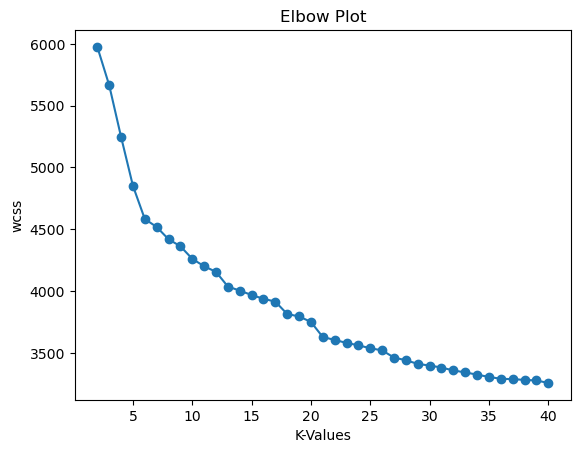

In [11]:
# Let's find the best k-value
k_values = np.arange(2, 41)

wcss = []

for i in k_values:
    km = KMeans(n_clusters=i, random_state=11)
    km.fit(X_final)
    wcss.append(km.inertia_)


# Let's the graph between k_values vs. wcss
plt.plot(k_values, wcss, marker='o')
plt.xlabel("K-Values")
plt.ylabel("wcss")
plt.title("Elbow Plot")
plt.show()

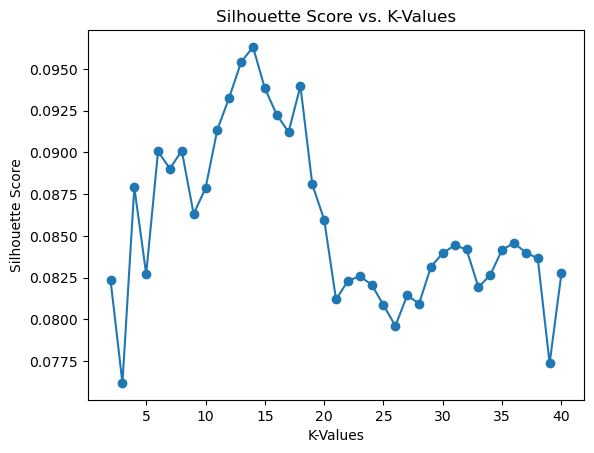

In [12]:
sil_score = []

for i in k_values:
    km = KMeans(n_clusters=i, random_state=11)
    labels = km.fit_predict(X_final)
    score = silhouette_score(X_final, labels)
    sil_score.append(score)


# k_value vs. silhouette score plot
plt.plot(k_values, sil_score, marker='o')
plt.xlabel("K-Values")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs. K-Values")
plt.show()

From both the plots we get the best k = 14

In [13]:
# Let's build the model
best_k = 14
kmeans_final = KMeans(n_clusters=best_k, random_state=11)
kmeans_final.fit(X_final)
df_display['cluster'] = kmeans_final.labels_

# Checking for no of titles landed in each cluster
print("Title per cluster:\n", df_display['cluster'].value_counts().sort_index())

Title per cluster:
 cluster
0     146
1      70
2     194
3     117
4     280
5     247
6     187
7      68
8      81
9      49
10     71
11     46
12    265
13     83
Name: count, dtype: int64


In [14]:
# Let's check cluster 0,1 and 9 to see what shows grouped together
print("--- Sample Titles from Cluster 0 ---")
display(df_display[df_display['cluster'] == 0][['title', 'type', 'release_year', 'genres', 'production_countries', 'imdb_score']].head(5))

print("--- Sample Titles from Cluster 1 ---")
display(df_display[df_display['cluster'] == 1][['title', 'type', 'release_year', 'genres', 'production_countries', 'imdb_score']].head(5))

print("--- Sample Titles from Cluster 9 ---")
display(df_display[df_display['cluster'] == 9][['title', 'type', 'release_year', 'genres', 'production_countries', 'imdb_score']].head(5))

--- Sample Titles from Cluster 0 ---


,title,type,release_year,genres,production_countries,imdb_score
35,iPartment,SHOW,2009,"[comedy, drama, animation, romance, scifi, fan...",[CN],6.5
103,The Legend of the Condor Heroes,SHOW,2008,"[drama, action, romance, fantasy, animation]",[CN],7.3
194,Scarlet Heart,SHOW,2011,"[action, drama, fantasy, history, romance]",[CN],8.0
217,Love Actually,SHOW,2012,"[drama, romance]",[CN],5.3
254,Symphony of Fate,SHOW,2011,"[drama, romance]",[CN],8.0


--- Sample Titles from Cluster 1 ---


,title,type,release_year,genres,production_countries,imdb_score
66,Possessed,SHOW,2009,"[drama, horror, thriller]",[KR],7.5
125,Grudge: The Revolt of Gumiho,SHOW,2010,"[thriller, drama, fantasy]",[KR],7.4
163,Ghost,SHOW,2012,"[crime, action, drama, history, horror]",[KR],5.2
191,White Christmas,SHOW,2011,"[drama, crime, thriller]",[KR],8.1
212,Sign,SHOW,2011,"[crime, thriller]",[KR],8.0


--- Sample Titles from Cluster 9 ---


,title,type,release_year,genres,production_countries,imdb_score
5,The Storm Riders,MOVIE,1998,"[action, fantasy]",[HK],6.3
6,The Maidens of Heavenly Mountains,MOVIE,1994,"[action, fantasy]",[HK],5.8
9,Fight Back to School 2,MOVIE,1992,"[comedy, action, crime]",[HK],6.6
82,Romantic Warriors,MOVIE,2003,"[fantasy, horror, comedy, romance, action]",[KR],4.4
120,The Grace Lee Project,MOVIE,2005,[documentation],[US],7.4


In [19]:
# Defining a recommendation function
def recommend_titles(title_name, top_n=5):
    matches = df_display[df_display['title'].str.lower() == title_name.lower()]

    if matches.empty:
        return f"Title '{title_name}' not found."

    target_cluster = matches['cluster'].iloc[0]

    recs = df_display[
        (df_display['cluster'] == target_cluster) & 
        (df_display['title'].str.lower() != title_name.lower())
    ].sort_values(by='imdb_score', ascending=False)

    return recs[['title', 'type', 'release_year', 'genres', 'production_countries', 'imdb_score']].head(top_n)

# Let's test on some of the titles
print("--- Recommendations for Scarlet Heart ---")
display(recommend_titles("Scarlet Heart", top_n=5))

print("--- Recommendation for Flirting Scholar ---")
display(recommend_titles("Flirting Scholar", top_n=5))


--- Recommendations for Scarlet Heart ---


,title,type,release_year,genres,production_countries,imdb_score
1684,Ms. Cupid in Love,SHOW,2022,"[scifi, comedy, drama, fantasy, history, romance]",[CN],9.1
457,Nirvana in Fire,SHOW,2015,"[drama, history, romance, thriller, action, fa...",[CN],9.0
1066,An Oriental Odyssey,SHOW,2018,"[scifi, romance, action, drama, fantasy]",[CN],9.0
805,My Story For You,SHOW,2018,"[drama, romance]",[CN],8.9
1197,Winter Begonia,SHOW,2020,"[drama, war, history, music, romance]",[CN],8.8


--- Recommendation for Flirting Scholar ---


,title,type,release_year,genres,production_countries,imdb_score
1067,Nuts,MOVIE,2018,"[comedy, romance, drama]",[CN],8.200000
482,Soul Mate,MOVIE,2016,"[drama, romance]",[CN],7.400000
1252,Goodbye Mother,MOVIE,2019,"[comedy, drama, romance]",[VN],7.400000
11,Fly Me to Polaris,MOVIE,1999,"[fantasy, drama, romance]",[HK],7.200000
1895,My Sweet Dear,MOVIE,2021,[romance],[],7.086058


In [21]:
# Creating directories and saving all trained objects
os.makedirs("../models", exist_ok=True)

artifacts = {
    "kmeans": kmeans_final,
    "imputer": imputer,
    "scaler": scaler,
    "ohe": ohe,
    "mlb_genres": mlb_genres,
    "mlb_countries": mlb_countries,
    "tfidf": tfidf
}
joblib.dump(artifacts, "../models/recommender_artifacts.joblib")

# Let's export final display table with cluster assignments for app.py
df_display.to_pickle("../data/processed/clustered_titles.pkl")
df_display.to_csv("../data/processed/clustered_titles.csv", index=False)

print("All model artifacts and cluster_titles saved successfully!")

All model artifacts and cluster_titles saved successfully!
